# Data Analysis and Visualization



Reference: 
- Histograms
    - K/D Ratio
    - Net Worth by end of game
    - Use Wraith and Abrams (Wraith is generally regarded as a character that needs a lot of money, and Abrams is regarded as a character that doesn't need as much to have an impact) 

In [3]:
import matplotlib.pyplot as mp
import pandas as pd

# load CSV files as dataframes
matchFrame = pd.read_csv("match_lengths.csv")
playerFrame = pd.read_csv("player_stats.csv")

### Histograms
We will be creating histograms to view 4 different numerical variables: Kills, Deaths, K/D Ratio (kills / deaths), and net worth (the amount of money earned throughout the whole match).

Additionally, we'll be looking at versions for all characters, as well as breakdowns for two specific characters: Wraith and Abrams. These two characters were chosen because, generally, Wraith is regarded as a character that needs a lot of money in order to have maximum impact, but once she does, she tends to get a lot of kills. In contrast, Abrams is a character that is regarded as useful without needing to have nearly as much money as Wraith, but is also generally known for setting up kills rather than actually finishing them. 

As a hypothesis, I expect a rough bell curve for all of these statistics, with Abrams' K/D ratio and net worth having lower peaks than Wraith's. 

#### K/D Data Setup (TODO: Rework into graphs for JUST kills and JUST deaths)
We'll be making 3 lists: one for all players, and two for tracking specific characters, Wraith and Abrams by default. 

Note that if the player died 0 times, their K/D ratio would be infinite. In this case, we just add their number of kills to the list instead of infinity. This does very slightly affect the data, but I believe that using the player's total number of kills instead of infinity makes sense in context.

In [4]:
# Defining the two characters of interests
CHARACTERONE = "Abrams"
CHARACTERTWO = "Wraith"

dataDict = {
    "characterOne":{
        "kills":[],
        "deaths":[],
        "kd":[]
    },
    "characterTwo":{
        "kills":[],
        "deaths":[],
        "kd":[]
    },
    "allCharacters":{
        "kills":[],
        "deaths":[],
        "kd":[]
    },
}

for player in playerFrame.iloc:
    # check which character we're on, and add it to the corresponding list
    if player["character"] == CHARACTERONE:
        dataDict["characterOne"]["kills"].append(player["kills"])
        dataDict["characterOne"]["deaths"].append(player["deaths"])

        if player["deaths"] == 0:
            dataDict["characterOne"]["kd"].append(player["kills"])
        else:
            dataDict["characterOne"]["kd"].append(player["kills"]/player["deaths"])
        
    if player["character"] == CHARACTERTWO:
        dataDict["characterTwo"]["kills"].append(player["kills"])
        dataDict["characterTwo"]["deaths"].append(player["deaths"])

        if player["deaths"] == 0:
            dataDict["characterTwo"]["kd"].append(player["kills"])
        else:
            dataDict["characterTwo"]["kd"].append(player["kills"]/player["deaths"])

    # in all cases, add the player's K/D to the main list
    dataDict["allCharacters"]["kills"].append(player["kills"])
    dataDict["allCharacters"]["deaths"].append(player["deaths"])

    if player["deaths"] == 0:
        dataDict["allCharacters"]["kd"].append(player["kills"])
    else:
        dataDict["allCharacters"]["kd"].append(player["kills"]/player["deaths"])

print(f"{CHARACTERONE} data points: {len(dataDict["characterOne"]["kills"])} | {CHARACTERTWO} data points: {len(dataDict["characterTwo"]["kills"])} | Total data points: {len(dataDict["allCharacters"]["kills"])}")

Abrams data points: 326 | Wraith data points: 441 | Total data points: 12000


#### All Characters Data
<b>Note:</b> The K/D histogram has been truncated, as the vast majority of the data was within the range 1-5. There are some outliers, but they will be examined in later graphs.

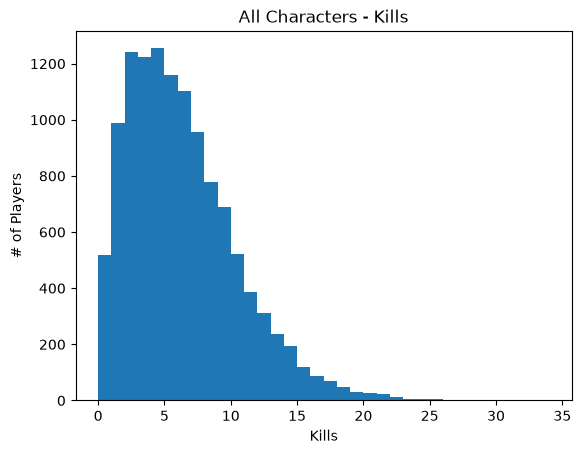

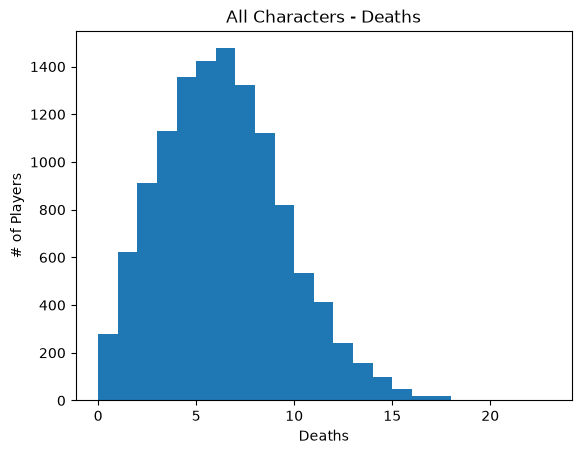

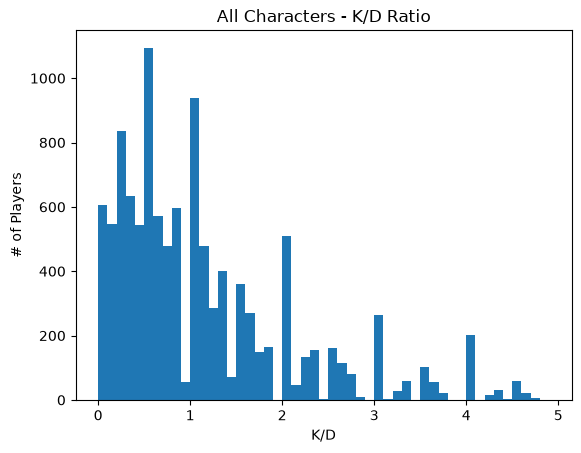

In [19]:
# kills for all characters
maxKills = max(dataDict["allCharacters"]["kills"])
bins = [x for x in range(maxKills)]

mp.hist(dataDict["allCharacters"]["kills"], bins=bins)
mp.title("All Characters - Kills")
mp.xlabel("Kills")
mp.ylabel("# of Players")
mp.show()

# deaths for all characters
maxDeaths = max(dataDict["allCharacters"]["deaths"])
bins = [x for x in range(maxDeaths)]

mp.hist(dataDict["allCharacters"]["deaths"], bins=bins)
mp.title("All Characters - Deaths")
mp.xlabel("Deaths")
mp.ylabel("# of Players")
mp.show()

# k/d for all characters
maxKd = max(dataDict["allCharacters"]["kd"])
bins = [x*0.1 for x in range(50)]

mp.hist(dataDict["allCharacters"]["kd"], bins=bins)
mp.title("All Characters - K/D Ratio")
mp.xlabel("K/D")
mp.ylabel("# of Players")
mp.show()